In [4]:
# Importing libraries
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler, OneHotEncoder, LabelEncoder
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report
import ppscore as pps
import seaborn as sns
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')

In [6]:
columns = ['age', 'workclass', 'fnlwgt', 'education', 'education-num',
           'marital-status', 'occupation', 'relationship', 'race', 'sex',
           'capital-gain', 'capital-loss', 'hours-per-week', 'native-country', 'income']
data = pd.read_csv('adult_with_headers[1].csv', header=None, names=columns, na_values=' ?')

In [7]:
# 1. Data Exploration and Preprocessing
print("Basic Data Exploration:")
print(data.info())  # Check data types and missing values
print(data.describe())  # Summary statistics

Basic Data Exploration:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32562 entries, 0 to 32561
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   age             32562 non-null  object
 1   workclass       30726 non-null  object
 2   fnlwgt          32562 non-null  object
 3   education       32562 non-null  object
 4   education-num   32562 non-null  object
 5   marital-status  32562 non-null  object
 6   occupation      30719 non-null  object
 7   relationship    32562 non-null  object
 8   race            32562 non-null  object
 9   sex             32562 non-null  object
 10  capital-gain    32562 non-null  object
 11  capital-loss    32562 non-null  object
 12  hours-per-week  32562 non-null  object
 13  native-country  31979 non-null  object
 14  income          32562 non-null  object
dtypes: object(15)
memory usage: 3.7+ MB
None
          age workclass  fnlwgt education education-num       marital-sta

In [8]:
# Checking missing values
print("\nMissing values in each column:")
print(data.isnull().sum())


Missing values in each column:
age                  0
workclass         1836
fnlwgt               0
education            0
education-num        0
marital-status       0
occupation        1843
relationship         0
race                 0
sex                  0
capital-gain         0
capital-loss         0
hours-per-week       0
native-country     583
income               0
dtype: int64


In [9]:
# Handling missing values by removing rows with missing values
data = data.dropna()  # Simple approach, alternatively you can impute

In [10]:
# Scaling numerical features
numerical_features = ['age', 'fnlwgt', 'education-num', 'capital-gain', 'capital-loss', 'hours-per-week']

In [13]:
print(data[numerical_features].dtypes)

age               object
fnlwgt            object
education-num     object
capital-gain      object
capital-loss      object
hours-per-week    object
dtype: object


In [14]:
for col in numerical_features:
    data[col] = pd.to_numeric(data[col], errors='coerce')

In [15]:
data = data.dropna(subset=numerical_features)

In [16]:
for col in numerical_features:
    data[col].fillna(data[col].median(), inplace=True)

In [17]:
from sklearn.preprocessing import StandardScaler

# Standard scaling on numerical features
standard_scaler = StandardScaler()
data_standard_scaled = pd.DataFrame(standard_scaler.fit_transform(data[numerical_features]), columns=numerical_features)

In [18]:
# Min-Max Scaling
min_max_scaler = MinMaxScaler()
data_min_max_scaled = pd.DataFrame(min_max_scaler.fit_transform(data[numerical_features]), columns=numerical_features)

In [19]:
# Discuss scenarios for scaling
print("\nStandard Scaling is preferred when data follows a normal distribution.")
print("Min-Max Scaling is used when we need the data in a specific range, often for algorithms like neural networks.")


Standard Scaling is preferred when data follows a normal distribution.
Min-Max Scaling is used when we need the data in a specific range, often for algorithms like neural networks.


In [20]:
# 2. Encoding Techniques
# Apply One-Hot Encoding for categorical variables with less than 5 categories
categorical_features = data.select_dtypes(include=['object']).columns.tolist()

In [21]:
for feature in categorical_features:
    if data[feature].nunique() < 5:
        # One-Hot Encoding
        data = pd.concat([data, pd.get_dummies(data[feature], prefix=feature)], axis=1)
        data.drop(feature, axis=1, inplace=True)
    else:
        # Label Encoding for categories with more than 5 unique values
        le = LabelEncoder()
        data[feature] = le.fit_transform(data[feature])

In [22]:
# Discuss pros and cons of encoding
print("\nOne-Hot Encoding: Pros - useful for non-ordinal categories, Cons - can cause dimensionality explosion.")
print("Label Encoding: Pros - compact representation, Cons - can introduce ordinal relationships that may not exist.")


One-Hot Encoding: Pros - useful for non-ordinal categories, Cons - can cause dimensionality explosion.
Label Encoding: Pros - compact representation, Cons - can introduce ordinal relationships that may not exist.


In [23]:
# 3. Feature Engineering
# Create new features
data['age_squared'] = data['age'] ** 2  # Squared age feature to capture non-linearity
data['capital_net'] = data['capital-gain'] - data['capital-loss']  # New feature for net capital

In [24]:
print("\nNew features created: 'age_squared' and 'capital_net'.")


New features created: 'age_squared' and 'capital_net'.


In [25]:
# Apply log transformation to a skewed feature
data['log_hours_per_week'] = np.log1p(data['hours-per-week'])  # Log transformation to reduce skewness
print("Log transformation applied to 'hours-per-week'.")

Log transformation applied to 'hours-per-week'.


In [26]:
# 4. Feature Selection
# Use Isolation Forest to identify and remove outliers
iso_forest = IsolationForest(contamination=0.05, random_state=42)
outliers = iso_forest.fit_predict(data[numerical_features])
data['outliers'] = outliers
print(f"\nOutliers detected: {sum(data['outliers'] == -1)}")


Outliers detected: 1509


In [27]:
# Keep only non-outliers
data = data[data['outliers'] != -1].drop(columns=['outliers'])

In [28]:
# PPS Analysis
pps_matrix = pps.matrix(data)
print("\nPPS Matrix:\n", pps_matrix)


PPS Matrix:
                       x                   y  ppscore            case  \
0                   age                 age      1.0  predict_itself   
1                   age           workclass      0.0      regression   
2                   age              fnlwgt      0.0      regression   
3                   age           education      0.0      regression   
4                   age       education-num      0.0      regression   
..                  ...                 ...      ...             ...   
395  log_hours_per_week       income_ <=50K      0.0      regression   
396  log_hours_per_week        income_ >50K      0.0      regression   
397  log_hours_per_week         age_squared      0.0      regression   
398  log_hours_per_week         capital_net      0.0      regression   
399  log_hours_per_week  log_hours_per_week      1.0  predict_itself   

     is_valid_score               metric  baseline_score   model_score  \
0              True                 None       

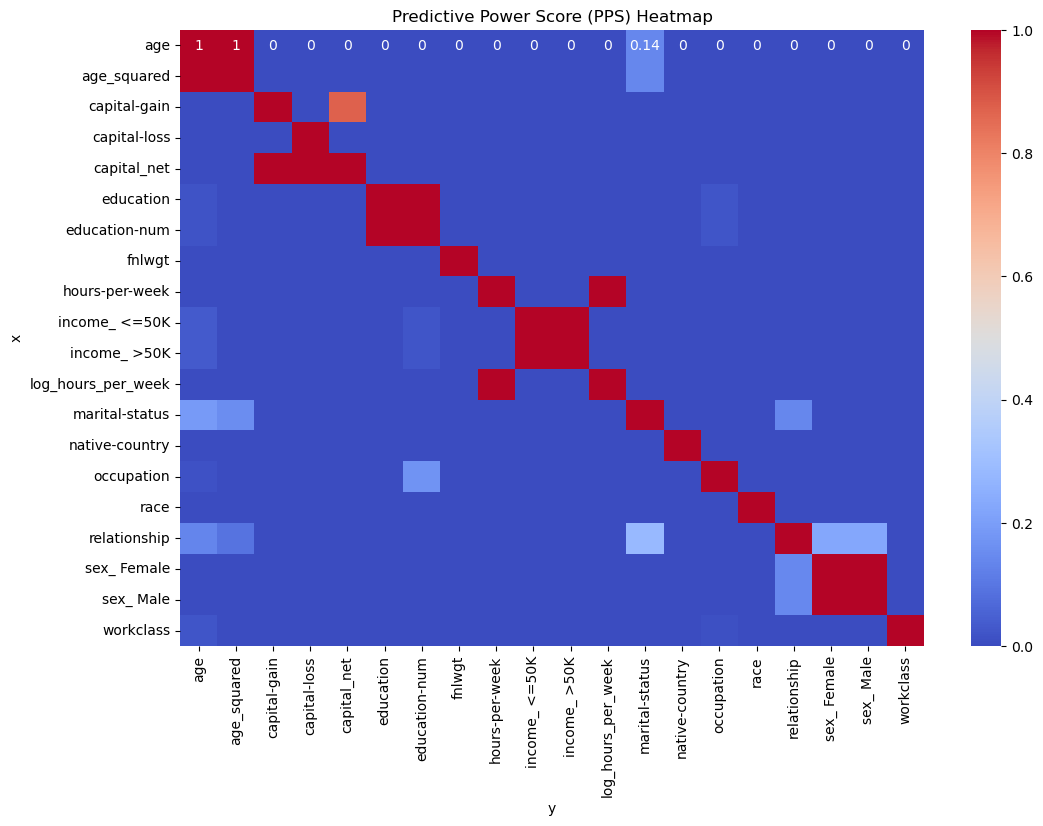

In [29]:
# Visualizing PPS matrix
plt.figure(figsize=(12, 8))
sns.heatmap(pps.matrix(data).pivot('x', 'y', 'ppscore'), annot=True, cmap='coolwarm', vmin=0, vmax=1)
plt.title("Predictive Power Score (PPS) Heatmap")
plt.show()

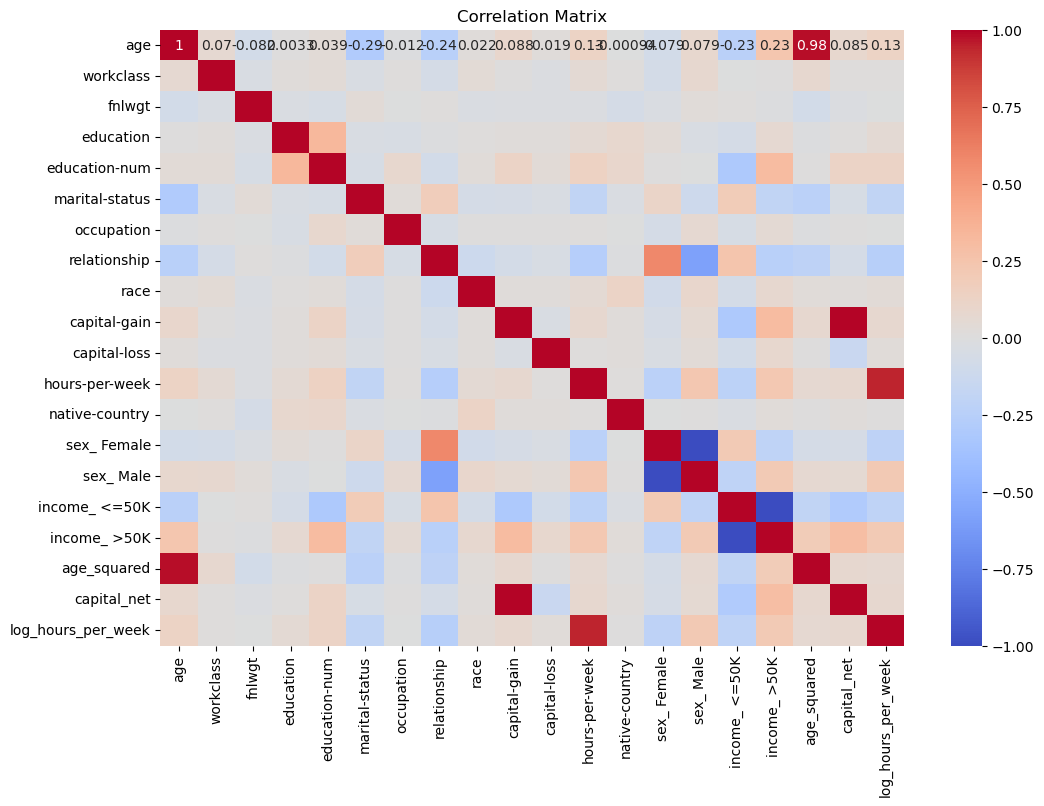

In [30]:
# Correlation matrix for comparison
correlation_matrix = data.corr()
plt.figure(figsize=(12, 8))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [31]:
# Compare PPS with Correlation Matrix
print("\nPPS focuses on predictive power, even for non-linear relationships, while correlation measures linear relationships only.")


PPS focuses on predictive power, even for non-linear relationships, while correlation measures linear relationships only.
